<a href="https://colab.research.google.com/github/Ignacio3000/TP_Filtros_Activos/blob/main/TP_sintesis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Pasaaltos Butterworth - Orden calculado: 3
Pasaaltos Butterworth - Frecuencia de corte Wn (rad/s): 20064.84
Pasabanda Chebyshev II - Orden calculado: 2
Pasabanda Chebyshev II - Frecuencias Wn (rad/s): [ 3385.41733725 33584.58688377]


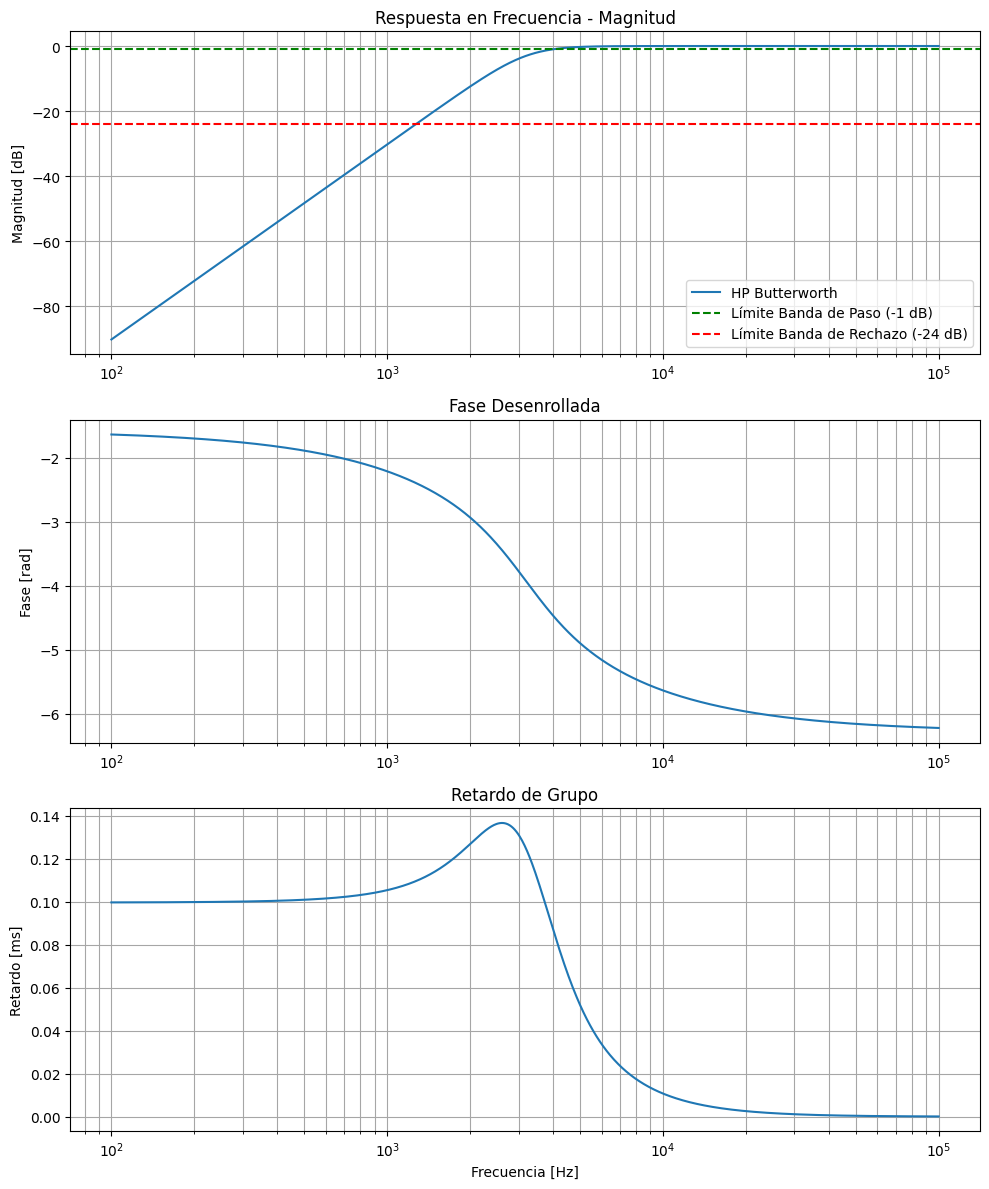

In [5]:
import numpy as np
import scipy.signal as sig
import sympy as sp
import matplotlib.pyplot as plt
import pandas as pd

# --- Especificaciones Generales ---
# Atenuación máxima en banda de paso y mínima en rechazo (en dB)
Ap = 1.0
As = 24.0

# --- Especificaciones del Pasaaltos (HP) ---
# Frecuencias en Hz[cite: 2]
f_pass_hp = 4000
f_stop_hp = 1000

# Conversión a rad/s (w = 2*pi*f)
w_pass_hp = 2 * np.pi * f_pass_hp
w_stop_hp = 2 * np.pi * f_stop_hp

# --- Especificaciones del Pasabanda (BP) ---
# Frecuencias en Hz
f_pass_bp = [1200, 2400]
f_stop_bp = [500, 5500]

# Conversión a rad/s[cite: 2]
w_pass_bp = [2 * np.pi * f for f in f_pass_bp]
w_stop_bp = [2 * np.pi * f for f in f_stop_bp]

# ==========================================
# EJEMPLO DE CÁLCULO: HP Butterworth
# ==========================================
# 1. Obtener orden y frecuencia de diseño
# btype='highpass' indica que es un filtro pasaaltos, analog=True indica filtro analógico
N_hp_butt, Wn_hp_butt = sig.buttord(w_pass_hp, w_stop_hp, Ap, As, analog=True)

# 2. Obtener función de transferencia en zpk y sos[cite: 2]
z_hp_butt, p_hp_butt, k_hp_butt = sig.butter(N_hp_butt, Wn_hp_butt, btype='high', analog=True, output='zpk')
sos_hp_butt = sig.zpk2sos(z_hp_butt, p_hp_butt, k_hp_butt)

print(f"Pasaaltos Butterworth - Orden calculado: {N_hp_butt}")
print(f"Pasaaltos Butterworth - Frecuencia de corte Wn (rad/s): {Wn_hp_butt:.2f}")

# ==========================================
# EJEMPLO DE CÁLCULO: BP Chebyshev II
# ==========================================
# 1. Obtener orden y frecuencia de diseño[cite: 2]
N_bp_cheb2, Wn_bp_cheb2 = sig.cheb2ord(w_pass_bp, w_stop_bp, Ap, As, analog=True)

# 2. Obtener función de transferencia en zpk y sos[cite: 2]
z_bp_cheb2, p_bp_cheb2, k_bp_cheb2 = sig.cheby2(N_bp_cheb2, As, Wn_bp_cheb2, btype='bandpass', analog=True, output='zpk')
sos_bp_cheb2 = sig.zpk2sos(z_bp_cheb2, p_bp_cheb2, k_bp_cheb2)

print(f"Pasabanda Chebyshev II - Orden calculado: {N_bp_cheb2}")
print(f"Pasabanda Chebyshev II - Frecuencias Wn (rad/s): {Wn_bp_cheb2}")

# Definir un vector de frecuencias angulares (w) en escala logarítmica
# Vamos desde 100 Hz hasta 100 kHz aproximadamente (en rad/s) para ver bien las bandas
w = np.logspace(np.log10(2*np.pi*100), np.log10(2*np.pi*100000), 1000)

# Calcular la respuesta en frecuencia H(jw) para el Pasaaltos Butterworth (calculado en el paso anterior)
w, H_hp_butt = sig.freqs_zpk(z_hp_butt, p_hp_butt, k_hp_butt, worN=w)

# Cálculos requeridos por la guía:
# 1. Magnitud en dB[cite: 2]
mag_dB = 20 * np.log10(np.abs(H_hp_butt))

# 2. Fase desenrollada en radianes[cite: 2]
fase_desenrollada = np.unwrap(np.angle(H_hp_butt))

# 3. Retardo de grupo (derivada negativa de la fase respecto a w)[cite: 2]
# Se usa np.gradient para aproximar d(fase)/d(w)
retardo_grupo = -np.gradient(fase_desenrollada, w)

# --- Creación de los gráficos ---
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 12))

# Gráfico de Magnitud
ax1.semilogx(w / (2*np.pi), mag_dB, label='HP Butterworth') # Eje X en Hz para mayor claridad
ax1.set_title('Respuesta en Frecuencia - Magnitud')
ax1.set_ylabel('Magnitud [dB]')
ax1.grid(True, which="both", ls="-", color='0.65')
ax1.axhline(-Ap, color='g', linestyle='--', label='Límite Banda de Paso (-1 dB)')
ax1.axhline(-As, color='r', linestyle='--', label='Límite Banda de Rechazo (-24 dB)')
ax1.legend()

# Gráfico de Fase
ax2.semilogx(w / (2*np.pi), fase_desenrollada)
ax2.set_title('Fase Desenrollada')
ax2.set_ylabel('Fase [rad]')
ax2.grid(True, which="both", ls="-", color='0.65')

# Gráfico de Retardo de Grupo
ax3.semilogx(w / (2*np.pi), retardo_grupo * 1000) # Escalado a milisegundos
ax3.set_title('Retardo de Grupo')
ax3.set_ylabel('Retardo [ms]')
ax3.set_xlabel('Frecuencia [Hz]')
ax3.grid(True, which="both", ls="-", color='0.65')

plt.tight_layout()
plt.show()
